# 04 · Modelos predictivos y validación interna (OE3, OE4 · H-2, H-3, H-4)

**Modelos:**
- RL con 4 variables continuas: réplica del semestre 1, como línea base.
- RL básica (no invasiva).
- RL extendida (+ imagen).
- Árbol CART, con profundidad y tamaño de hoja elegidos por validación cruzada interna (es decir, validación cruzada anidada).
- Random Forest, como referencia de un modelo flexible.

**Validación:**
- Validación cruzada estratificada 5 × 20, con las **mismas 100 particiones** para todos los modelos.
- Bootstrap de optimismo de Harrell (500 réplicas) para las regresiones logísticas.

**Métricas:**
- Discriminación: AUC, con IC 95 % de DeLong.
- Calibración: pendiente, intercepto y Brier.
- Utilidad clínica: sensibilidad, especificidad, VPP y VPN con umbral 0,5 y con el umbral que garantiza sensibilidad ≥ 90 %.

**Comparaciones:** t corregido de Nadeau-Bengio y DeLong.

> ⏱ Tiempo de ejecución: unos 2 minutos. Lo que más pesa es la validación cruzada (100 particiones × 5 modelos, con un árbol anidado de 60 ajustes y un bosque de 300 árboles por partición), que se paraleliza en todos los núcleos.

In [1]:
%run ./00_configuracion.ipynb
df, cc = load_processed()

In [2]:
from joblib import Parallel, delayed
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

## 1. Definición de modelos, métricas y pruebas

In [3]:
def _preprocessor(predictors, scale=True):
    cat = [v for v in predictors if v in CATEGORICAL]
    num = [v for v in predictors if v not in CATEGORICAL]
    num_tf = StandardScaler() if scale else "passthrough"
    return ColumnTransformer([
        ("num", num_tf, num),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), cat),
    ], verbose_feature_names_out=False)


def model_specs():
    """Modelos candidatos. Cada uno: (nombre corto, etiqueta, predictores, estimador)."""
    lr = LogisticRegression(C=1.0, l1_ratio=0, solver="lbfgs", max_iter=5000)  # L2
    tree = GridSearchCV(
        DecisionTreeClassifier(random_state=SEED),
        {"max_depth": [2, 3, 4, 5], "min_samples_leaf": [5, 10, 20]},
        scoring="roc_auc", cv=StratifiedKFold(5, shuffle=True, random_state=SEED))
    rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, max_features="sqrt",
                                random_state=SEED, n_jobs=1)
    return [
        ("s1", "RL 4 continuas (semestre 1)", PRED_SEMESTRE1, lr),
        ("basico", "RL básica (no invasiva)", PRED_BASICO, lr),
        ("extendido", "RL extendida (+ imagen)", PRED_EXTENDIDO, lr),
        ("arbol", "Árbol CART (extendido)", PRED_EXTENDIDO, tree),
        ("rf", "Random Forest (extendido)", PRED_EXTENDIDO, rf),
    ]


def make_pipeline(predictors, estimator):
    scale = isinstance(estimator, LogisticRegression)
    return Pipeline([("prep", _preprocessor(predictors, scale)), ("clf", clone(estimator))])


def threshold_metrics(y, p, thr):
    yhat = (p >= thr).astype(int)
    tp = int(((yhat == 1) & (y == 1)).sum()); fn = int(((yhat == 0) & (y == 1)).sum())
    tn = int(((yhat == 0) & (y == 0)).sum()); fp = int(((yhat == 1) & (y == 0)).sum())
    sdiv = lambda a, b: a / b if b else np.nan
    return {"umbral": float(thr), "VP": tp, "FN": fn, "VN": tn, "FP": fp,
            "sensibilidad": sdiv(tp, tp + fn), "especificidad": sdiv(tn, tn + fp),
            "VPP": sdiv(tp, tp + fp), "VPN": sdiv(tn, tn + fn),
            "exactitud": sdiv(tp + tn, len(y))}


def threshold_for_sensitivity(y, p, target):
    fpr, tpr, thr = roc_curve(y, p)
    idx = np.argmax(tpr >= target)
    return float(min(thr[idx], 1.0))


def calibration_stats(y, p):
    eps = 1e-6
    lp = np.log(np.clip(p, eps, 1 - eps) / (1 - np.clip(p, eps, 1 - eps)))
    m = sm.Logit(y, sm.add_constant(lp)).fit(disp=0)
    m_int = sm.GLM(y, np.ones_like(lp), family=sm.families.Binomial(), offset=lp).fit()
    return {"pendiente_calibracion": float(m.params[1]),
            "intercepto_calibracion_en_grande": float(m_int.params[0]),
            "brier": float(brier_score_loss(y, p))}


def corrected_resampled_ttest(diff, n_train, n_test):
    """Nadeau & Bengio (2003): t corregido para métricas de validación cruzada repetida."""
    k = len(diff)
    mean, var = np.mean(diff), np.var(diff, ddof=1)
    se = np.sqrt((1 / k + n_test / n_train) * var)
    t = mean / se
    p = 2 * stats.t.sf(abs(t), k - 1)
    tcrit = stats.t.ppf(1 - ALPHA / 2, k - 1)
    return {"diferencia_media": float(mean), "IC95_inf": float(mean - tcrit * se),
            "IC95_sup": float(mean + tcrit * se), "t": float(t), "p": float(p)}


def cross_validate(df):
    """Validación cruzada estratificada 5 x 20 sobre la misma muestra y particiones.

    Devuelve el AUC de cada una de las 100 particiones (estimador principal del
    desempeño) y las probabilidades fuera de muestra de la PRIMERA repetición
    (5 pliegues: cada paciente se predice exactamente una vez con un modelo que no
    lo vio). Estas últimas alimentan curvas ROC, calibración, DeLong y umbrales.
    No se promedian las 20 repeticiones porque eso equivale a un ensamble y
    sobrestima el desempeño de modelos inestables como el árbol.
    """
    y = df["ec"].values
    rskf = RepeatedStratifiedKFold(n_splits=CV_FOLDS, n_repeats=CV_REPEATS,
                                   random_state=SEED)
    splits = list(rskf.split(df, y))
    specs = model_specs()

    def run_split(tr, te):
        out = {}
        for key, _, preds, est in specs:
            pipe = make_pipeline(preds, est)
            pipe.fit(df.iloc[tr][preds], y[tr])
            p = pipe.predict_proba(df.iloc[te][preds])[:, 1]
            bp = pipe.named_steps["clf"].best_params_ if key == "arbol" else None
            out[key] = (roc_auc_score(y[te], p), brier_score_loss(y[te], p), p, bp)
        return out

    res = Parallel(n_jobs=-1)(delayed(run_split)(tr, te) for tr, te in splits)
    auc = {s[0]: [r[s[0]][0] for r in res] for s in specs}
    brier = {s[0]: [r[s[0]][1] for r in res] for s in specs}
    tree_params = [r["arbol"][3] for r in res]
    oof = {s[0]: np.full(len(df), np.nan) for s in specs}
    for i in range(CV_FOLDS):  # primera repetición: cada paciente una sola vez
        te = splits[i][1]
        for key in oof:
            oof[key][te] = res[i][key][2]
    assert not any(np.isnan(v).any() for v in oof.values())
    n_test = len(splits[0][1]); n_train = len(splits[0][0])
    return {"specs": specs, "auc": auc, "brier": brier, "oof": oof, "y": y,
            "tree_params": tree_params, "n_train": n_train, "n_test": n_test}


def bootstrap_optimism(df, predictors, estimator, n_boot=N_BOOTSTRAP):
    """AUC aparente, optimismo y AUC corregido por optimismo (Harrell, 2015)."""
    y = df["ec"].values
    X = df[predictors]
    pipe = make_pipeline(predictors, estimator).fit(X, y)
    apparent = roc_auc_score(y, pipe.predict_proba(X)[:, 1])
    rng = np.random.default_rng(SEED)
    opt = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(df), len(df))
        if len(np.unique(y[idx])) < 2:
            continue
        pb = make_pipeline(predictors, estimator).fit(X.iloc[idx], y[idx])
        auc_boot = roc_auc_score(y[idx], pb.predict_proba(X.iloc[idx])[:, 1])
        auc_orig = roc_auc_score(y, pb.predict_proba(X)[:, 1])
        opt.append(auc_boot - auc_orig)
    optimism = float(np.mean(opt))
    return {"auc_aparente": float(apparent), "optimismo": optimism,
            "auc_corregido": float(apparent - optimism), "n_boot": len(opt)}

In [4]:
def _midrank(x):
    j = np.argsort(x)
    z = x[j]
    n = len(x)
    t = np.zeros(n)
    i = 0
    while i < n:
        k = i
        while k < n and z[k] == z[i]:
            k += 1
        t[i:k] = 0.5 * (i + k - 1) + 1
        i = k
    out = np.empty(n)
    out[j] = t
    return out


def _delong_components(y, preds):
    y = np.asarray(y)
    pos, neg = preds[:, y == 1], preds[:, y == 0]
    m, n = pos.shape[1], neg.shape[1]
    k = preds.shape[0]
    tx = np.array([_midrank(r) for r in pos])
    ty = np.array([_midrank(r) for r in neg])
    tz = np.array([_midrank(r) for r in np.hstack([pos, neg])])
    auc = tz[:, :m].sum(axis=1) / (m * n) - (m + 1) / (2 * n)
    v01 = (tz[:, :m] - tx) / n
    v10 = 1 - (tz[:, m:] - ty) / m
    s = np.cov(v01) / m + np.cov(v10) / n
    return auc, np.atleast_2d(s)


def delong_ci(y, p):
    auc, s = _delong_components(y, np.vstack([p]))
    se = float(np.sqrt(s[0, 0]))
    z = stats.norm.ppf(1 - ALPHA / 2)
    return float(auc[0]), se, float(auc[0] - z * se), float(min(1, auc[0] + z * se))


def delong_test(y, p1, p2):
    auc, s = _delong_components(y, np.vstack([p1, p2]))
    diff = auc[0] - auc[1]
    var = s[0, 0] + s[1, 1] - 2 * s[0, 1]
    z = diff / np.sqrt(var)
    return {"auc_1": float(auc[0]), "auc_2": float(auc[1]), "diferencia": float(diff),
            "z": float(z), "p": float(2 * stats.norm.sf(abs(z)))}

## 2. Validación cruzada 5 × 20

In [5]:
t0 = time.time()
cv = cross_validate(cc)
print(f"Validación cruzada: {time.time() - t0:.0f} s")
y = cv["y"]
names = {s[0]: s[1] for s in cv["specs"]}
perf_rows, aucs_ci, calib, thr_info = [], {}, {}, {}
for key, label, preds, est in cv["specs"]:
    a = np.array(cv["auc"][key])
    auc_oof, se, lo, hi = delong_ci(y, cv["oof"][key])
    aucs_ci[key] = (auc_oof, se, lo, hi)
    calib[key] = calibration_stats(y, cv["oof"][key])
    thr90 = threshold_for_sensitivity(y, cv["oof"][key], TARGET_SENSITIVITY)
    m05 = threshold_metrics(y, cv["oof"][key], 0.5)
    m90 = threshold_metrics(y, cv["oof"][key], thr90)
    thr_info[key] = {"umbral_0.5": m05, "umbral_sens90": m90}
    perf_rows.append({
        "modelo": label, "clave": key, "n_predictores": len(preds),
        "AUC_CV_media": a.mean(), "AUC_CV_P2.5": np.percentile(a, 2.5), "AUC_CV_P97.5": np.percentile(a, 97.5),
        "AUC_OOF_DeLong": auc_oof, "AUC_OOF_IC_inf": lo, "AUC_OOF_IC_sup": hi,
        "Brier_CV": np.mean(cv["brier"][key]), "pendiente_calibracion": calib[key]["pendiente_calibracion"],
        "sens_0.5": m05["sensibilidad"], "esp_0.5": m05["especificidad"], "VPP_0.5": m05["VPP"], "VPN_0.5": m05["VPN"],
        "umbral_sens90": thr90, "sens_u90": m90["sensibilidad"], "esp_u90": m90["especificidad"], "VPN_u90": m90["VPN"]})
perf = pd.DataFrame(perf_rows)
perf.to_csv(TABLES / "tabla3_desempeno_modelos.csv", index=False)
show = perf[["modelo", "AUC_CV_media", "AUC_CV_P2.5", "AUC_CV_P97.5", "Brier_CV",
             "pendiente_calibracion", "sens_0.5", "esp_0.5", "esp_u90"]].copy()
for c in show.columns[1:]:
    show[c] = show[c].map(lambda v: f"{v:.3f}".replace(".", ","))
to_latex(show, TABLES / "tabla3_desempeno_modelos.tex",
         "Desempeño en validación cruzada estratificada 5 × 20 (media y percentiles 2,5–97,5 del AUC).",
         "tab:desempeno", header=["Modelo", "AUC", "P2,5", "P97,5", "Brier", "Pend. calib.",
                                  "Sens. (0,5)", "Esp. (0,5)", "Esp. (sens. 90 %)"])
display(show)

Validación cruzada: 47 s


,modelo,AUC_CV_media,AUC_CV_P2.5,AUC_CV_P97.5,Brier_CV,pendiente_calibracion,sens_0.5,esp_0.5,esp_u90
0,RL 4 continuas (semestre 1),"0,749","0,612","0,865","0,205","0,934","0,650","0,769","0,344"
1,RL básica (no invasiva),"0,874","0,794","0,949","0,146","0,907","0,752","0,844","0,613"
2,RL extendida (+ imagen),"0,909","0,829","0,964","0,120","0,836","0,788","0,875","0,700"
3,Árbol CART (extendido),"0,842","0,715","0,940","0,163","0,258","0,737","0,875","0,519"
4,Random Forest (extendido),"0,910","0,833","0,964","0,127","1,587","0,759","0,875","0,719"


## 3. Comparación pareada de modelos (H-3, H-4)

In [6]:
comps = {}
for a_, b_ in [("extendido", "basico"), ("basico", "s1"), ("extendido", "arbol"), ("extendido", "rf"), ("rf", "arbol")]:
    diff = np.array(cv["auc"][a_]) - np.array(cv["auc"][b_])
    comps[f"{a_}_vs_{b_}"] = {"nadeau_bengio": corrected_resampled_ttest(diff, cv["n_train"], cv["n_test"]),
                              "delong_oof": delong_test(y, cv["oof"][a_], cv["oof"][b_])}
comp_rows = [{"comparación": f"{names[k.split('_vs_')[0]]} vs {names[k.split('_vs_')[1]]}",
              "ΔAUC (IC 95 %)": f"{v['nadeau_bengio']['diferencia_media']:.3f} "
                                f"({v['nadeau_bengio']['IC95_inf']:.3f} a {v['nadeau_bengio']['IC95_sup']:.3f})".replace(".", ","),
              "p Nadeau-Bengio": fmt_p(v["nadeau_bengio"]["p"]), "p DeLong": fmt_p(v["delong_oof"]["p"])}
             for k, v in comps.items()]
pd.DataFrame(comp_rows).to_csv(TABLES / "tabla4_comparacion_modelos.csv", index=False)
to_latex(pd.DataFrame(comp_rows), TABLES / "tabla4_comparacion_modelos.tex",
         "Comparación pareada del AUC entre modelos (t corregido de Nadeau-Bengio y DeLong).", "tab:comparacion")
display(pd.DataFrame(comp_rows))

,comparación,ΔAUC (IC 95 %),p Nadeau-Bengio,p DeLong
0,RL extendida (+ imagen) vs RL básica (no invas...,"0,035 (0,008 a 0,062)","0,012","0,021"
1,RL básica (no invasiva) vs RL 4 continuas (sem...,"0,125 (0,070 a 0,180)","< 0,001","< 0,001"
2,RL extendida (+ imagen) vs Árbol CART (extendido),"0,067 (0,021 a 0,113)","0,004","0,003"
3,RL extendida (+ imagen) vs Random Forest (exte...,"-0,001 (-0,018 a 0,016)","0,936","0,908"
4,Random Forest (extendido) vs Árbol CART (exten...,"0,068 (0,026 a 0,109)","0,002","< 0,001"


## 4. Corrección de optimismo por bootstrap (H-2)

In [7]:
lr = [s for s in cv["specs"] if s[0] == "basico"][0][3]
boot = {k: bootstrap_optimism(cc, preds, lr) for k, preds in [("basico", PRED_BASICO), ("extendido", PRED_EXTENDIDO)]}
display(pd.DataFrame(boot))

,basico,extendido
auc_aparente,0.901004,0.934991
optimismo,0.021115,0.019734
auc_corregido,0.879888,0.915257
n_boot,500.000000,500.000000


## 5. Árbol de decisión final (hiperparámetros más frecuentes en la validación cruzada)

Hiperparámetros modales: {'max_depth': 4, 'min_samples_leaf': 10} (elegidos en 32 % de las particiones)


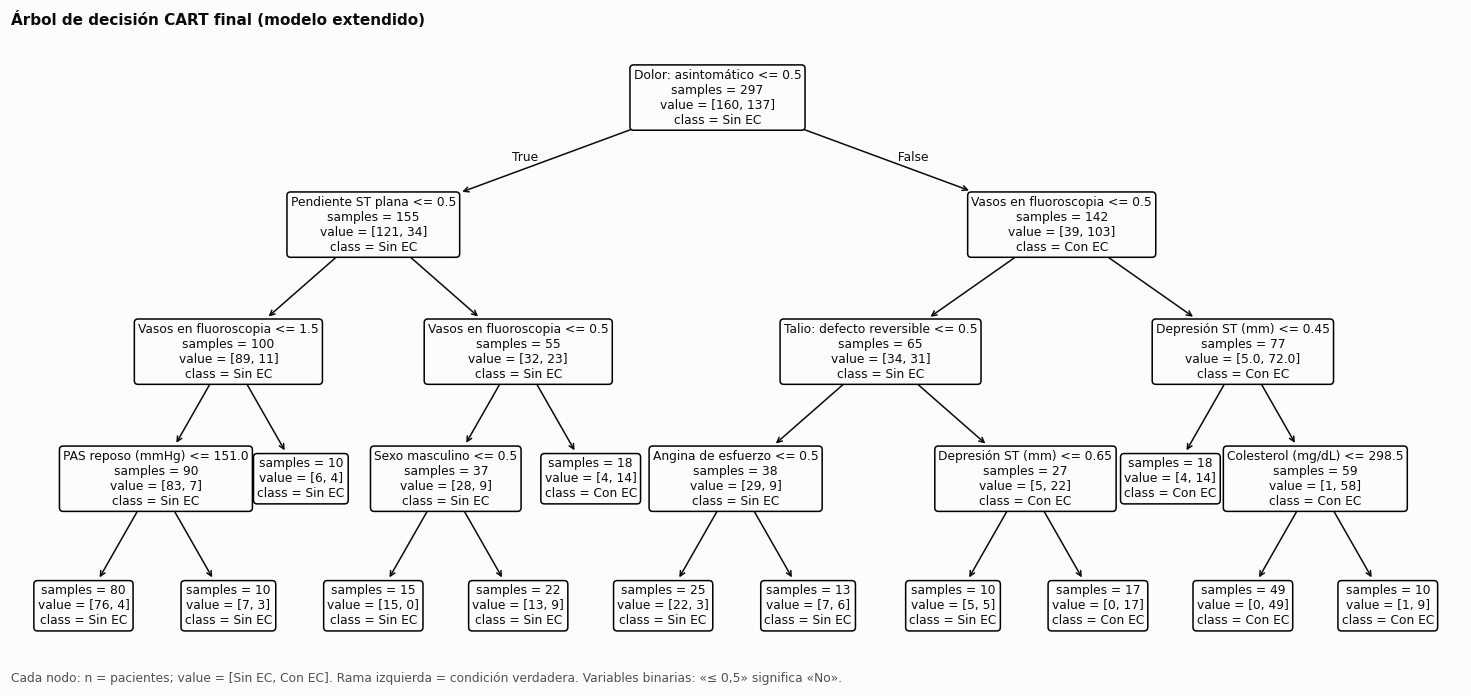

In [8]:
TREE_NAMES = {
    "age": "Edad (años)", "sex": "Sexo masculino", "trestbps": "PAS reposo (mmHg)",
    "chol": "Colesterol (mg/dL)", "fbs": "Glucemia > 120", "restecg_anormal": "ECG reposo anormal",
    "thalach": "FC máxima (lpm)", "exang": "Angina de esfuerzo", "oldpeak": "Depresión ST (mm)",
    "ca": "Vasos en fluoroscopia", "cp_2": "Dolor: angina atípica", "cp_3": "Dolor: no anginoso",
    "cp_4": "Dolor: asintomático", "slope_2": "Pendiente ST plana", "slope_3": "Pendiente ST descendente",
    "thal_6": "Talio: defecto fijo", "thal_7": "Talio: defecto reversible",
}


def fig_arbol(pipe, feature_names):
    setup()
    names = [TREE_NAMES.get(f, f) for f in feature_names]
    fig, ax = plt.subplots(figsize=(17, 7.5))
    plot_tree(pipe.named_steps["clf"], feature_names=names, class_names=GROUP_LABELS,
              filled=False, rounded=True, impurity=False, proportion=False, fontsize=8, ax=ax)
    ax.text(0.0, -0.02, "Cada nodo: n = pacientes; value = [Sin EC, Con EC]. Rama izquierda = condición verdadera. "
            "Variables binarias: «≤ 0,5» significa «No».", transform=ax.transAxes, fontsize=8, color=K["ink2"])
    ax.set_title("Árbol de decisión CART final (modelo extendido)")
    save(fig, "fig09_arbol_decision")


modal = Counter(tuple(sorted(p.items())) for p in cv["tree_params"]).most_common(1)[0]
tree_params = dict(modal[0])
print(f"Hiperparámetros modales: {tree_params} (elegidos en {100 * modal[1] / len(cv['tree_params']):.0f} % de las particiones)")
tree_pipe = make_pipeline(PRED_EXTENDIDO, DecisionTreeClassifier(random_state=SEED, **tree_params))
tree_pipe.fit(cc[PRED_EXTENDIDO], y)
feat = list(tree_pipe.named_steps["prep"].get_feature_names_out())
fig_arbol(tree_pipe, feat)
importances = dict(sorted(zip(feat, tree_pipe.named_steps["clf"].feature_importances_.round(4)), key=lambda kv: -kv[1]))

## 6. Discriminación, calibración y utilidad clínica

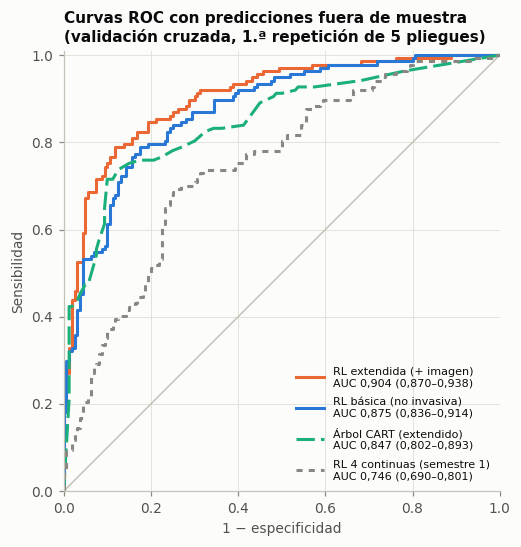

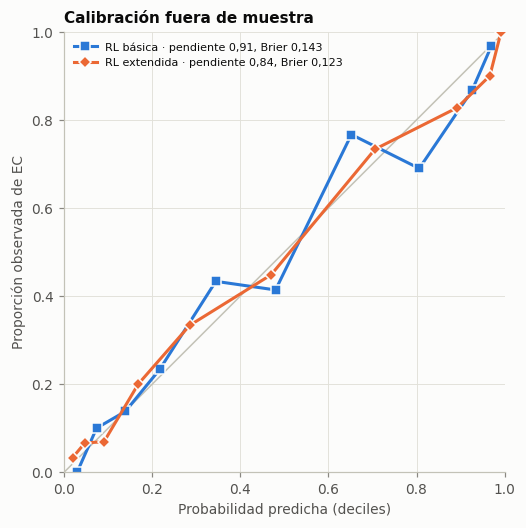

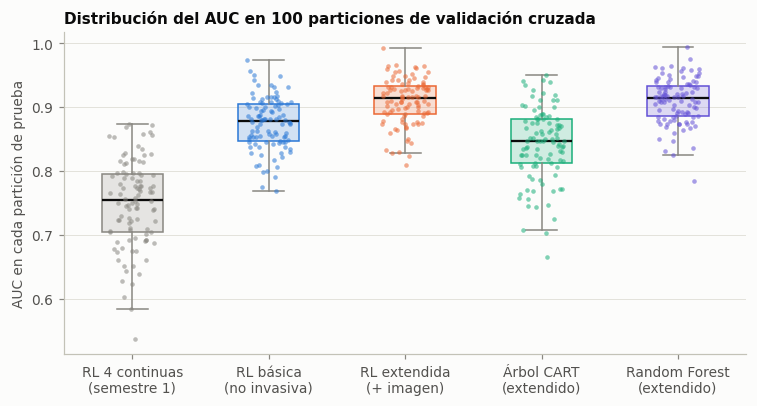

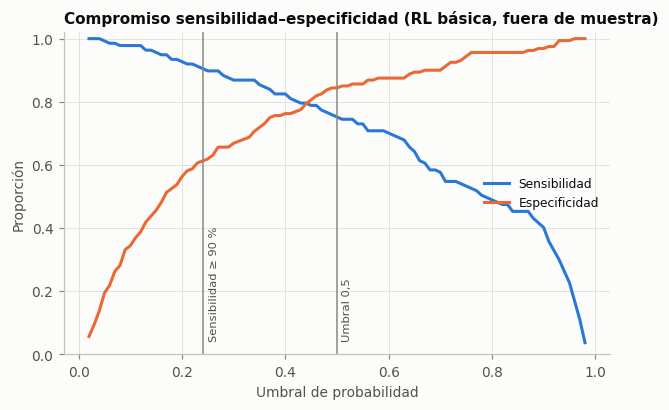

In [9]:
def fig_roc(cv, aucs_ci):
    setup()
    styles = {"basico": (K["m_basico"], "-"), "extendido": (K["m_extendido"], "-"),
              "arbol": (K["m_arbol"], (0, (6, 2))), "s1": (K["m_s1"], (0, (2, 2)))}
    names = {s[0]: s[1] for s in cv["specs"]}
    fig, ax = plt.subplots(figsize=(5.6, 5.2))
    ax.plot([0, 1], [0, 1], color=K["axis"], lw=1)
    for key in ["extendido", "basico", "arbol", "s1"]:
        fpr, tpr, _ = roc_curve(cv["y"], cv["oof"][key])
        col, ls = styles[key]
        a, _, lo, hi = aucs_ci[key]
        ax.plot(fpr, tpr, color=col, linestyle=ls,
                label=f"{names[key]}\nAUC {a:.3f} ({lo:.3f}–{hi:.3f})".replace(".", ","))
    ax.set_xlabel("1 − especificidad"); ax.set_ylabel("Sensibilidad")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.01); ax.set_aspect("equal")
    ax.legend(loc="lower right", fontsize=7.3, handlelength=2.5, labelspacing=0.8)
    ax.set_title("Curvas ROC con predicciones fuera de muestra\n(validación cruzada, 1.ª repetición de 5 pliegues)")
    save(fig, "fig07_curvas_roc")


def fig_calibracion(cv, calib):
    setup()
    fig, ax = plt.subplots(figsize=(5.4, 5.2))
    ax.plot([0, 1], [0, 1], color=K["axis"], lw=1)
    y = cv["y"]
    for key, col, mk, lab in [("basico", K["m_basico"], "s", "RL básica"),
                              ("extendido", K["m_extendido"], "D", "RL extendida")]:
        p = cv["oof"][key]
        bins = pd.qcut(p, 10, labels=False, duplicates="drop")
        d = pd.DataFrame({"p": p, "y": y, "b": bins}).groupby("b").agg(p=("p", "mean"), y=("y", "mean"))
        ax.plot(d.p, d.y, color=col, marker=mk, markersize=6, markeredgecolor=K["surface"],
                label=f"{lab} · pendiente {calib[key]['pendiente_calibracion']:.2f}, "
                      f"Brier {calib[key]['brier']:.3f}".replace(".", ","))
    ax.set_xlabel("Probabilidad predicha (deciles)"); ax.set_ylabel("Proporción observada de EC")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
    ax.legend(loc="upper left", fontsize=7.3)
    ax.set_title("Calibración fuera de muestra")
    save(fig, "fig08_calibracion")


def fig_auc_cv(cv):
    setup(); rng = np.random.default_rng(SEED)
    order = ["s1", "basico", "extendido", "arbol", "rf"]
    colors = [K["m_s1"], K["m_basico"], K["m_extendido"], K["m_arbol"], K["m_rf"]]
    names = {s[0]: s[1] for s in cv["specs"]}
    fig, ax = plt.subplots(figsize=(8, 3.8))
    _box_strip(ax, [cv["auc"][k] for k in order], colors,
               [names[k].replace(" (", "\n(") for k in order], rng)
    ax.set_ylabel("AUC en cada partición de prueba")
    ax.set_title("Distribución del AUC en 100 particiones de validación cruzada")
    save(fig, "fig10_auc_validacion_cruzada")


def fig_umbral(cv, key, thr_sens):
    setup()
    y, p = cv["y"], cv["oof"][key]
    thr = np.linspace(0.02, 0.98, 97)
    sens = [((p >= t) & (y == 1)).sum() / (y == 1).sum() for t in thr]
    spec = [((p < t) & (y == 0)).sum() / (y == 0).sum() for t in thr]
    fig, ax = plt.subplots(figsize=(6.4, 3.8))
    ax.plot(thr, sens, color=K["m_basico"], label="Sensibilidad")
    ax.plot(thr, spec, color=K["m_extendido"], label="Especificidad")
    for t, lab in [(0.5, "Umbral 0,5"), (thr_sens, f"Sensibilidad ≥ {int(TARGET_SENSITIVITY*100)} %")]:
        ax.axvline(t, color=K["muted"], lw=1)
        ax.text(t + 0.01, 0.04, lab, fontsize=7.5, color=K["ink2"], rotation=90, va="bottom")
    ax.set_xlabel("Umbral de probabilidad"); ax.set_ylabel("Proporción")
    ax.set_ylim(0, 1.02); ax.legend(loc="center right")
    ax.set_title("Compromiso sensibilidad–especificidad (RL básica, fuera de muestra)")
    save(fig, f"fig11_umbral_{key}")


fig_roc(cv, aucs_ci)
fig_calibracion(cv, calib)
fig_auc_cv(cv)
fig_umbral(cv, "basico", perf.set_index("clave").loc["basico", "umbral_sens90"])

**Interpretación.**
- **H-2:** el modelo básico supera claramente AUC = 0,80. El límite inferior de su IC es mayor que 0,80, y su AUC corregido por optimismo también, así que se rechaza H0.
- **H-3:** añadir la imagen mejora el AUC de forma significativa pero modesta (≈ 0,035).
- **H-4:** la RL extendida discrimina mejor que el árbol. El árbol, además, está mal calibrado (pendiente ≪ 1, sobreajuste) y es inestable: sus hiperparámetros cambian entre particiones.
- **Random Forest:** no supera a la RL y su pendiente es > 1 (probabilidades demasiado conservadoras).
- **Conclusión metodológica:** la RL es la mejor opción por equilibrio entre desempeño, calibración e interpretabilidad.

In [10]:
save_json("04_prediccion", {"prediccion": {
    "desempeno": perf.set_index("clave").to_dict("index"), "comparaciones": comps, "bootstrap_optimismo": boot,
    "calibracion": calib, "umbrales": thr_info, "arbol_hiperparametros_modales": tree_params,
    "arbol_frecuencia_modal": modal[1] / len(cv["tree_params"]), "arbol_importancias": importances,
    "validacion": f"RepeatedStratifiedKFold({CV_FOLDS} x {CV_REPEATS}), semilla {SEED}"}})

PosixPath('/home/ana/code/Semestre_4/Healtech_1/Proyecto/results/json/04_prediccion.json')